<class 'pandas.core.frame.DataFrame'>



Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='object')



               age      anaemia  creatinine_phosphokinase     diabetes  \
count  5000.000000  5000.000000               5000.000000  5000.000000   
mean     60.288736     0.474400                586.760600     0.439400   
std      11.697243     0.499394                976.733979     0.496364   
min      40.000000     0.000000                 23.000000     0.000000   
25%      50.000000     0.000000                121.000000     0.000000   
50%      60.000000     0.000000                248.000000     0.000000   
75%      68.000000     1.000000                582.000000     1.000000   
max      95.000000     1.000000               7861.000000     1.000000   

       ejection_fraction  high_blood_pressure 

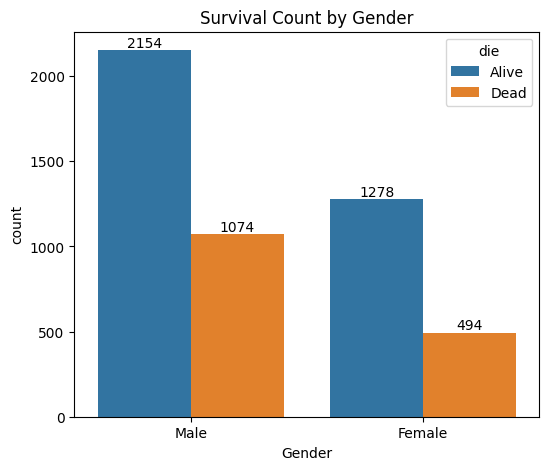

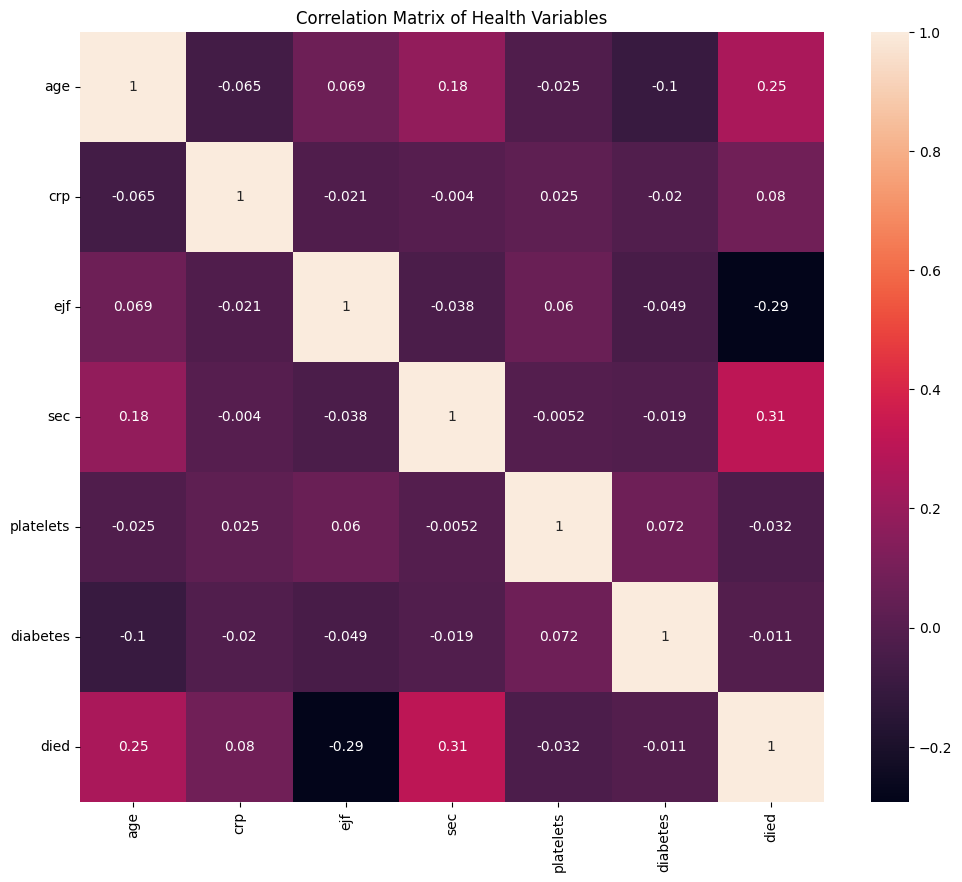

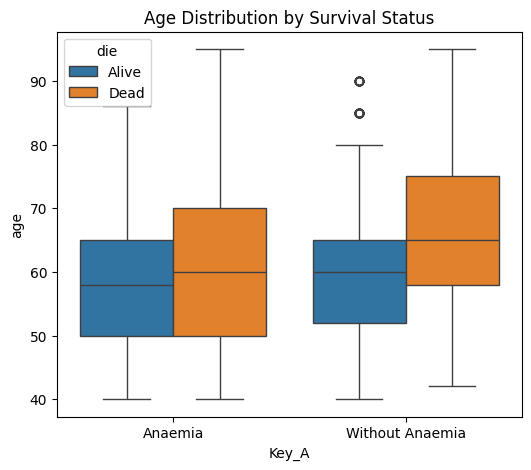

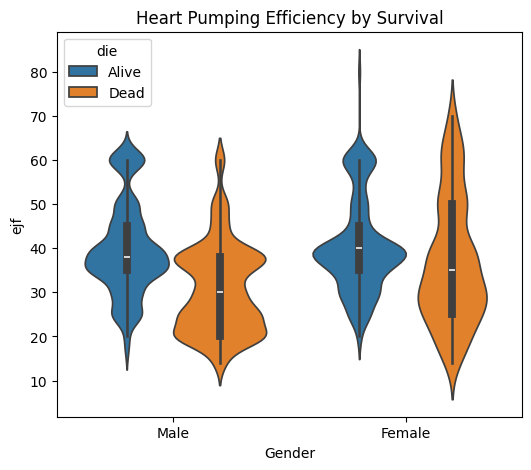

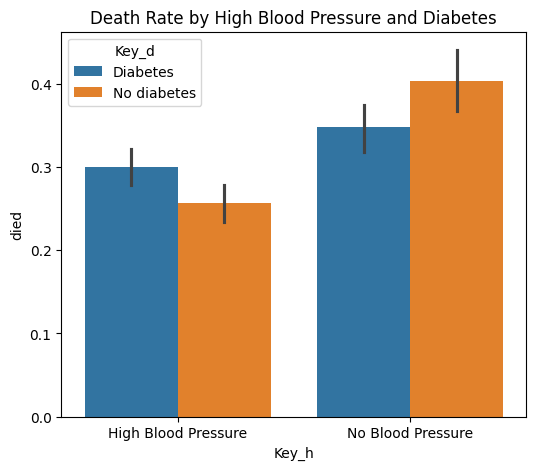

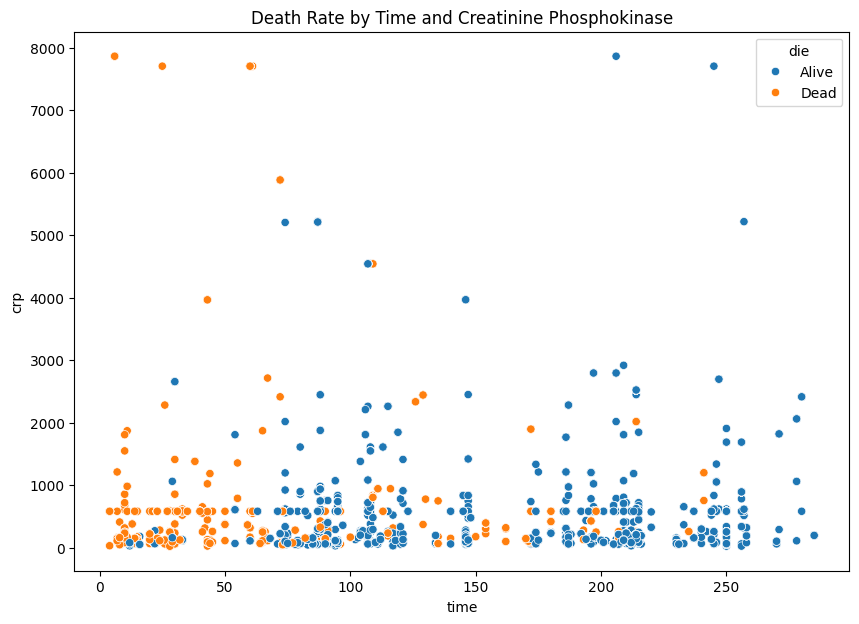

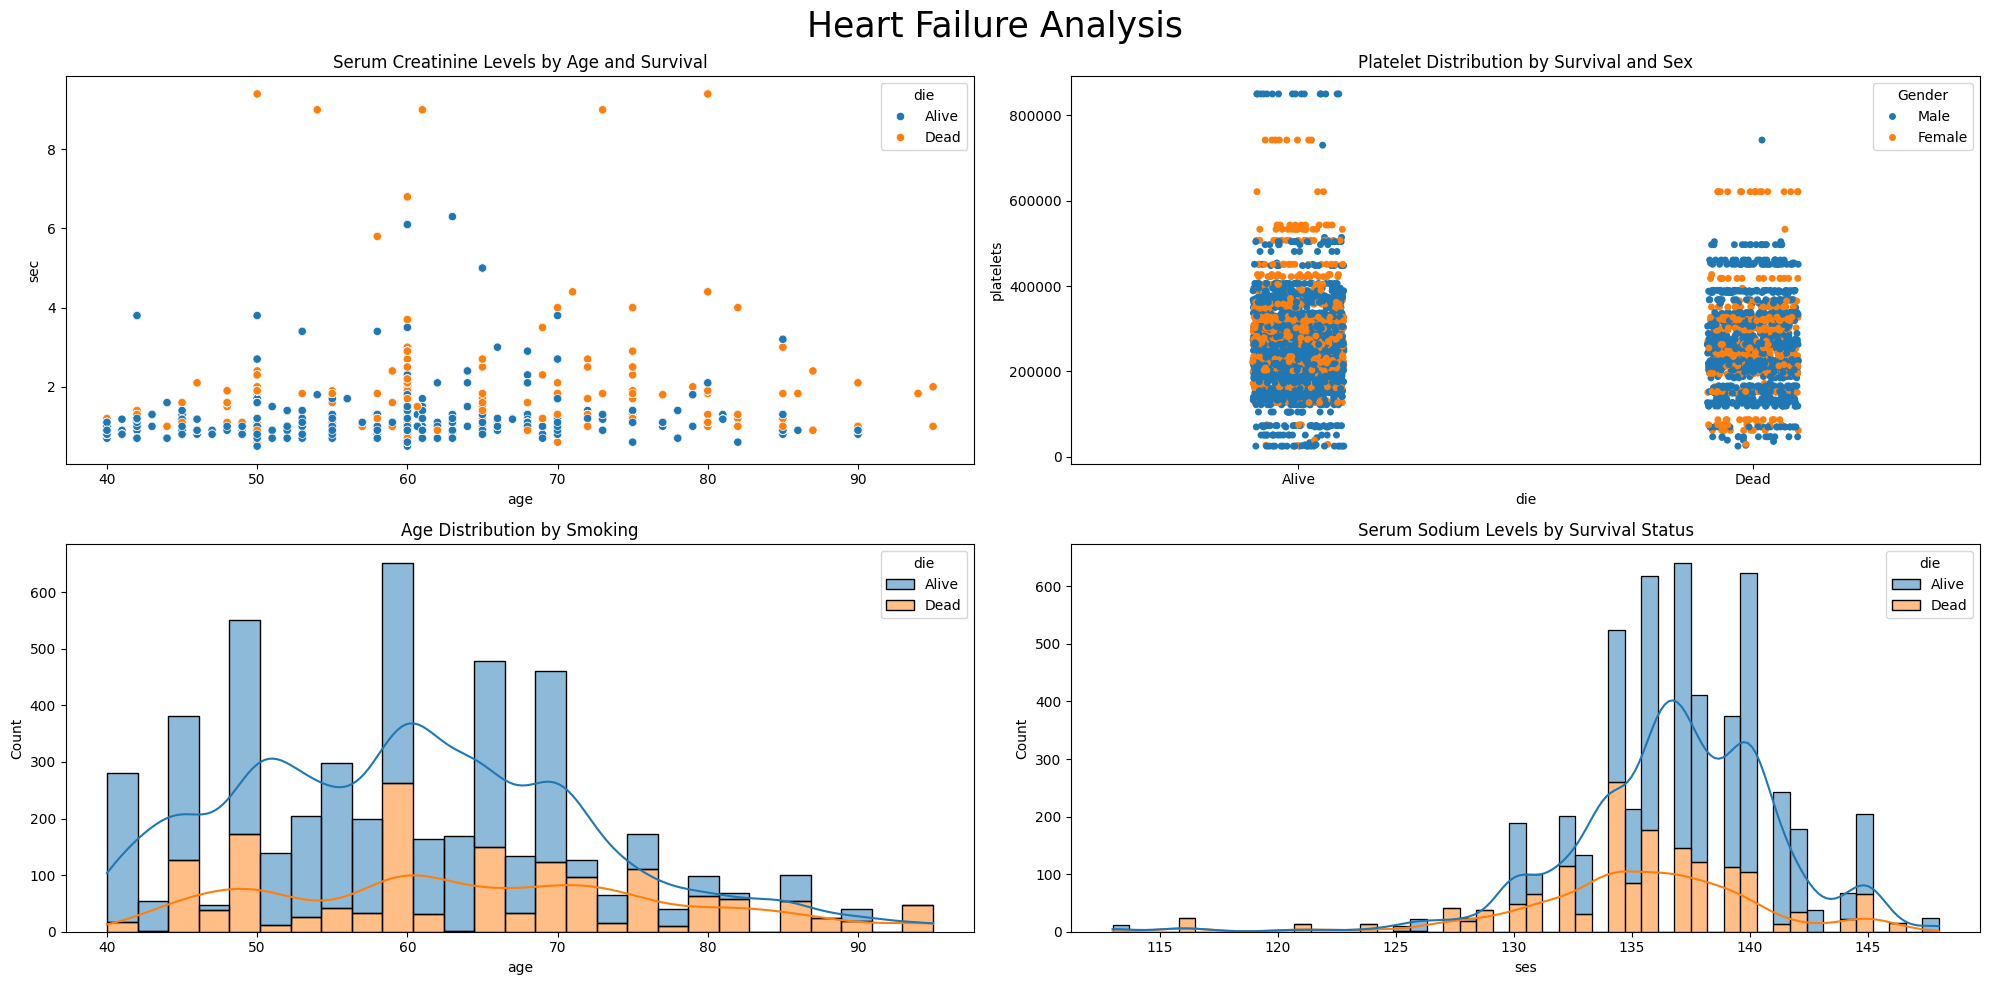




     dead_status
0          Alive
1          Alive
2          Alive
3          Alive
4           Dead
...          ...
4995       Alive
4996       Alive
4997        Dead
4998        Dead
4999       Alive

[5000 rows x 1 columns]
Index(['age', 'anaemia', 'crp', 'diabetes', 'ejf', 'hbp', 'platelets', 'sec',
       'ses', 'sex', 'smoking', 'time', 'died', 'Gender', 'die', 'Key_A',
       'Key_d', 'Key_h', 'Smoking', 'dead_status'],
      dtype='object')

X Dimension:  2
X Shape:  (5000, 12)
[[5.5000000e+01 0.0000000e+00 7.4800000e+02 0.0000000e+00 4.5000000e+01
  0.0000000e+00 2.6335803e+05 1.3000000e+00 1.3700000e+02 1.0000000e+00
  1.0000000e+00 8.8000000e+01]
 [6.5000000e+01 0.0000000e+00 5.6000000e+01 0.0000000e+00 2.5000000e+01
  0.0000000e+00 3.0500000e+05 5.0000000e+00 1.3000000e+02 1.0000000e+00
  0.0000000e+00 2.0700000e+02]
 [4.5000000e+01 0.0000000e+00 5.8200000e+02 1.0000000e+00 3.8000000e+01
  0.0000000e+00 3.1900000e+05 9.0000000e-01 1.4000000e+02 0.0000000e+00
  0.000000

In [ ]:
#List of libraries for Logistic Regression
import pandas as pd
import numpy as np
from numpy import random as ra
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

#Reading the file
File = 'heart_failure_clinical_records.csv'
df=pd.read_csv(File)
print(type(df))

# show the columns #
print("\n\n")
print(df.columns)

# show the columns #
print("\n\n")
print(df.describe())

#Show information of the file
print("\n\n")
print(df.info())

#Show first 5 rows each column
print("\n\n")
print(df.head())

#Before cleaning
print(f"\n\nMissing values before cleaning:\n{df.isnull().sum()}")

#Clean the File
print("\n\n")
print("\n\n")
new_cleaned=df.dropna()
df.dropna(inplace=True)
df = df.loc[df['age'] <= 100]
#Removing duplicate data
df_clean = df.drop_duplicates()
print(f"\nRemoved {len(df) - len(df_clean)} rows with missing data.")
print('\n\n')
#Rename the columns
df = df.rename(columns={
    'creatinine_phosphokinase': 'crp',
    'ejection_fraction': 'ejf',
    'high_blood_pressure': 'hbp',
    'serum_creatinine': 'sec',
    'serum_sodium': 'ses',
    'DEATH_EVENT': 'died'})
print(df.info())
print(f"\n\n{df.head()}")

#Analyse the data
print(f"\n\n{df.describe().T}")
print(f"\n\nThe minimum age is: {df['age'].min()}")
print(f"The highest age is: {df['age'].max()}")

#Key for Gender and Deaths
df['Gender'] = df['sex'].map({0: 'Female', 1: 'Male'})
df['die'] = df['died'].map({0: 'Alive', 1: 'Dead'})
## (Key for age and Anaemia)
df['Key_A'] = df['anaemia'].map({0: 'Anaemia', 1: 'Without Anaemia'})
# (Key for diabetes and high blood pressure)
df['Key_d'] = df['diabetes'].map({0: 'Diabetes', 1: 'No diabetes'})
df['Key_h'] = df['hbp'].map({0: 'High Blood Pressure', 1: 'No Blood Pressure'})
#Key for smoking
df['Smoking'] = df['smoking'].map({0: 'No', 1: 'Yes'})

#Analyse the data of Mens and Womens (died/alive)
print(f"\n\n{df[['Gender','die']].value_counts()}")
#Analyse the data in combinations
print(f"\n\n{df[['age','Gender','die']].value_counts()}")
#Boolean Data
print(f"\n\n{df[['hbp','Gender','anaemia','smoking','diabetes','die']].value_counts()}")
#Numerical Data
print(f"\n\n{df[['age','ejf','sec','Gender','time']].value_counts()}")
#groupby Boolean Data
print(f"\n\n{df.groupby(['hbp','Gender','anaemia','smoking','diabetes','die'])['die'].agg(['count'])}")
#groupby Numerical Data
print(f"\n\n{df.groupby(['ejf','sec','ses','time'])['age'].agg(['mean', 'median', 'count'])}")

# Correlation
print('\nCorrelation')
df_corr = df[['age', 'anaemia', 'crp', 'diabetes', 'ejf', 'hbp',
              'platelets', 'sec','ses', 'sex', 'smoking', 'time', 'died']]
print(df_corr.corr().abs()[['died']])
print('\n\n')
#New columns needed in Data Frame
df_plot=df[['die','Gender','Key_A','Key_d','Smoking','Key_h']].copy()
print('\n\n')

#----------------------------------------Graph's--------------------------------------------#

# countplot graph (death vs Gender)
plt.figure(figsize=(6, 5))
plt.title('Survival Count by Gender')
ax = sns.countplot(data=df, x='Gender', hue='die')

# Add values on top of each table
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=0)

# Print and save
plt.savefig('Survival Count by Gender.jpg')
plt.show()

print('\n\n')
#################################################################################################
# Correlation heatmap
plt.figure(figsize=(12, 10))
plt.title('Correlation Matrix of Health Variables', fontsize=12)
# Calculate correlations
Int_columns = ['age', 'crp', 'ejf', 'sec', 'platelets', 'diabetes', 'died']
Correlation = df[Int_columns].corr()
print('\n\n')
# Create the heatmap
heatmap = sns.heatmap(Correlation,annot=True,)
# Title and labels
plt.xticks(rotation=90)
plt.yticks(rotation=0)
# Show the plot
plt.savefig('Correlation Matrix of Health Variable.jpg')
plt.show()
print('\n\n')
############################################################################################################
#Age vs. Death Event
plt.figure(figsize=(6, 5))
sns.boxplot(x='Key_A', y='age', data=df, hue='die')
plt.title('Age Distribution by Survival Status')
plt.savefig('Age Distribution by survival.jpg')
############################################################################################################
print('\n\n')
#Ejection Fraction vs. Death
plt.figure(figsize=(6, 5))
sns.violinplot(x='Gender', y='ejf', data=df, hue='die')
plt.title('Heart Pumping Efficiency by Survival')
plt.savefig('Heart Pumping Efficiency by Survival.jpg')
plt.show()
print('\n\n')
###########################################################################################################
# Create (countplot) graph hbp against die
plt.figure(figsize=(6, 5))
sns.barplot(x='Key_h', y='died', hue='Key_d',data=df)
plt.title('Death Rate by High Blood Pressure and Diabetes')
plt.savefig('Death Rate by High Blood Pressure and Diabetes.jpg')
plt.show()
print('\n\n')
###########################################################################################################
# Scatterplot graph creatinine_phosphokinase vs time
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df,x='time',y="crp",hue='die')
plt.title('Death Rate by Time and Creatinine Phosphokinase')
plt.savefig('Death Rate by Time and Creatinine Phosphokinase.jpg')
plt.show()
print('\n\n')
###########################################################################################################
# Set up the subplot grid
fig6, axs = plt.subplots(nrows=2,ncols=2, figsize=(20,10))
plt.suptitle('Heart Failure Analysis', fontsize=25)

# Figure 1 (Scatterplot graph of Serum Creatinine vs Age)
axs[0, 0].set_title('Serum Creatinine Levels by Age and Survival')
sns.scatterplot(data=df,ax=axs[0,0],x='age',y='sec',hue='die')

# Figure 2 (Stripplot graph of Platelets)
axs[0, 1].set_title('Platelet Distribution by Survival and Sex')
sns.stripplot(ax=axs[0, 1],data=df,x='die',y='platelets',hue='Gender')

# Figure 3 (Distribution Plot of Smoking)
axs[1, 0].set_title('Age Distribution by Smoking')
#Key
sns.histplot(data=df,ax=axs[1, 0],x='age',hue='die',multiple='stack',kde=True)

# Figure 4 (Serum sodium level by survivals)
sns.histplot(ax=axs[1,1],data=df,x='ses',multiple='stack',hue='die',kde=True)
axs[1, 1].set_title('Serum Sodium Levels by Survival Status')

# Adjust layout
plt.tight_layout()
plt.savefig('Heart Failure Analysis.jpg')
plt.show()
print('\n\n')
#################################################################################################

died = {
    1 : 'Dead',
    0 : 'Alive'
}
df['dead_status'] = df['died'].map(died)

print(df[['dead_status']])

##################################################################################################
# MAchine learning begins........................................................................

# #Independent variables (all rows and columns except last one)
X = df.iloc[:, :-8].values

# Grab all rows, and only the last column
y = df.iloc[:, -1].values

print(df.columns)

# What does X look like
print()

print('X Dimension: ', X.ndim)
print('X Shape: ', X.shape)
print(X[:5])
print()

# What does Y look like
print('y Dimension: ', y.ndim)
print('y Shape: ', y.shape)
print(y[:5])
print()

# Spliting the data into 20% and 80% for training
X_train, X_test, y_train, y_test= train_test_split(X,y,random_state=40,test_size=0.2)

#Scale the features
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

# Creating Logistic Regression
my_regressor=LogisticRegression()
my_regressor.fit(X_train,y_train)


# Assess Accuracy - equivalent to Mean Absolute Error in Linear Regression
predictions = my_regressor.predict(X_test)
report = classification_report(y_test, predictions)
print(report)

print('\n\n')
#--------------------------------------------------------------------------------------#
#Predictions
random_index = ra.randint(0, len(X_test))
X_test_random = X_test[random_index].reshape(-1,12)
print('Input data columns: \t\tpclass gender relatives')
print('Random index: ', random_index)
print('Random record reshaped to 2-d is: ', X_test_random)
print()

# Make a Prediction with a random choice from X_test
random_prediction = my_regressor.predict(X_test_random)
random_probs = my_regressor.predict_proba(X_test_random)
print('Prediction: ', random_prediction[0])
print('Probabilities: ', random_probs)
for x in random_probs.reshape(-1):
  print(f'{round(x*100)}%')

print('\n\n\n')
#--------------------------------------------------------------------------------------#

#Make your own Predictions
# Input your independent data
age = float(input('Enter age: '))
anaemia = float(input('Enter anaemia: '))
crp = float(input('Enter creatinine_phosphokinase: ')) # Add this line
platelets = float(input('Enter platelets: '))
diabetes = float(input('Enter diabetes: '))
ejf = float(input('Enter ejection fraction: '))
hbp = float(input('Enter high blood pressure: '))
sec = float(input('Enter serum creatinine: '))
ses = float(input('Enter serum sodium: '))
sex = float(input('Enter sex: '))
smoking = float(input('Enter smoking: '))
time = float(input('Enter time: '))

# Convert input to an 2-d array
newX_array = np.array([
                        age,
                        anaemia,
                        crp, # Add crp to the array
                        platelets,
                        diabetes,
                        ejf,
                        hbp,
                        sec,
                        ses,
                        sex,
                        smoking,
                        time
                        ]).reshape(-1,12) # Now you have 12 elements to reshape

new_prediction = my_regressor.predict(newX_array)
new_probs = my_regressor.predict_proba(newX_array) # Fix typo here: newX__array to newX_array

# Print it out
print('Prediction:    ', new_prediction[0])
print('Probabilities: ', new_probs)
print()

print(f'The values you have provided: {newX_array}')

